In [1]:
!pip install -U "torch==2.6.0" "torchvision==0.21.0" "diffusers==0.35.1" "transformers==4.49.0" "safetensors==0.6.2" "huggingface-hub==0.34.4" "datasets==3.6.0" "pillow>=10,<13" "numpy>=2,<3" "pandas>=2.2,<4" "matplotlib>=3.8,<4" "ipython>=8,<10"

# Flickr30k text embedding baseline

In [2]:
import sys, subprocess, importlib.util, importlib.metadata, platform, os
from pathlib import Path

# Use the PyTorch backend only; skip transformers' TensorFlow/Flax imports (they need NumPy < 2).
os.environ.setdefault('USE_TF', '0')
os.environ.setdefault('USE_FLAX', '0')

required = {
    'torch': 'torch==2.6.0',
    'torchvision': 'torchvision==0.21.0',
    'diffusers': 'diffusers==0.35.1',
    'transformers': 'transformers==4.49.0',
    'safetensors': 'safetensors==0.6.2',
    'huggingface_hub': 'huggingface-hub==0.34.4',
    'datasets': 'datasets==3.6.0',
    'PIL': 'pillow>=10,<13',
    'numpy': 'numpy>=1.26,<3',
    'pandas': 'pandas>=2.2,<4',
    'matplotlib': 'matplotlib>=3.8,<4',
    'IPython': 'ipython>=8,<10',
}
missing = [spec for module, spec in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', *missing], check=True)
else:
    print('All required packages are installed in this kernel environment.')

# The installed pyarrow/datasets build needs NumPy 2.x, so upgrade before importing numpy.
if int(importlib.metadata.version('numpy').split('.')[0]) < 2:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-U', 'numpy>=2,<3'], check=True)
    print('Upgraded NumPy to 2.x; restart the kernel if it was already imported.')

import csv, hashlib, json, random, re, time, unicodedata, textwrap
from collections import Counter, defaultdict
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import diffusers
import transformers
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Markdown
from transformers import CLIPTokenizer, CLIPTextModel

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(min(8, os.cpu_count() or 1))
environment = {
    'python': sys.version.split()[0], 'platform': platform.platform(),
    'torch': torch.__version__, 'diffusers': diffusers.__version__,
    'transformers': transformers.__version__, 'device': DEVICE,
    'cuda_available': torch.cuda.is_available(),
    'gpu': torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None,
    'packages': {name: importlib.metadata.version(name) for name in
                 ['torchvision', 'safetensors', 'huggingface-hub', 'datasets', 'pillow', 'numpy', 'pandas', 'matplotlib']},
}
display(pd.DataFrame([{'component': k, 'value': str(v)} for k, v in environment.items() if k != 'packages']))

All required packages are installed in this kernel environment.


,component,value
0,python,3.12.2
1,platform,macOS-26.6.2-arm64-arm-64bit
2,torch,2.6.0
3,diffusers,0.35.1
4,transformers,4.49.0
5,device,cpu
6,cuda_available,False
7,gpu,None


In [3]:
N_PAIRS = 3000
IMAGE_SIZE = 512
SEED = 42
ENCODE_BATCH_SIZE = 8
MODEL_ID = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
MODEL_REVISION = '451f4fe16113bff5a5d2269ed5ad43b0592e9a14'
DATASET_ID = 'lmms-lab-encoder/flickr30k'
DATASET_REVISION = '765d117f3eec816f2bfdc2d73ebb50a6f77b86a4'

assert 1000 <= N_PAIRS <= 5000
current = Path.cwd().resolve()
if current.name == 'submission':
    NOTEBOOK_DIR = current
elif (current / 'submission' / 'flickr30k_text_embedding_baseline.ipynb').exists():
    NOTEBOOK_DIR = current / 'submission'
else:
    NOTEBOOK_DIR = current
ARTIFACTS = NOTEBOOK_DIR / 'artifacts'
ARTIFACTS.mkdir(parents=True, exist_ok=True)
PROCESSED = ARTIFACTS / 'processed'
(PROCESSED / 'images').mkdir(parents=True, exist_ok=True)

search_roots = [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents]
RAW = next((p / 'data/raw/flickr30k' for p in search_roots
            if (p / 'data/raw/flickr30k/captions.csv').is_file()), ARTIFACTS / 'raw/flickr30k')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE == 'cuda':
    torch.cuda.manual_seed_all(SEED)
STARTED_UTC = datetime.now(timezone.utc).isoformat()

def write_json(destination, value):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def file_sha256(filename):
    digest = hashlib.sha256()
    with Path(filename).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

print('Raw data:', RAW)
print('Artifacts:', ARTIFACTS)
print('Requested pairs:', N_PAIRS)

Raw data: /Users/snehamishra/Documents/DL2026FALL/IE7615_Generative_Project/artifacts/raw/flickr30k
Artifacts: /Users/snehamishra/Documents/DL2026FALL/IE7615_Generative_Project/artifacts
Requested pairs: 3000


In [4]:
# Standalone fallback: this code is only needed when the local raw dataset is absent.
if not (RAW / 'captions.csv').exists():
    from datasets import load_dataset
    (RAW / 'images').mkdir(parents=True, exist_ok=True)
    wanted = min(5500, N_PAIRS + 500)
    stream = load_dataset(DATASET_ID, split='test', revision=DATASET_REVISION, streaming=True)
    stream = stream.shuffle(seed=SEED, buffer_size=2048)
    downloaded = 0
    temporary = RAW / 'captions.csv.partial'
    with temporary.open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=['image', 'caption'])
        writer.writeheader()
        for record in stream:
            filename = f'{downloaded:06d}.png'
            record['image'].convert('RGB').save(RAW / 'images' / filename)
            descriptions = record['caption']
            descriptions = [descriptions] if isinstance(descriptions, str) else descriptions
            for caption in descriptions:
                writer.writerow({'image': filename, 'caption': caption})
            downloaded += 1
            if downloaded % 100 == 0:
                print(f'Downloaded {downloaded}/{wanted}', flush=True)
            if downloaded >= wanted:
                break
    assert downloaded >= N_PAIRS, 'Insufficient source images.'
    temporary.replace(RAW / 'captions.csv')
    write_json(RAW / 'source.json', {
        'dataset': DATASET_ID, 'revision': DATASET_REVISION, 'source_split': 'test',
        'images': downloaded, 'seed': SEED, 'sampling': 'stream shuffle buffer=2048, then take N',
        'source_url': f'https://huggingface.co/datasets/{DATASET_ID}',
    })
provenance = json.loads((RAW / 'source.json').read_text(encoding='utf-8')) if (RAW / 'source.json').exists() else {'source': 'user supplied local images and CSV'}
display(provenance)

{'dataset': 'lmms-lab-encoder/flickr30k',
 'revision': '765d117f3eec816f2bfdc2d73ebb50a6f77b86a4',
 'source_split': 'test',
 'images': 3500,
 'seed': 42,
 'sampling': 'stream shuffle buffer=2048, then take N',
 'source_url': 'https://huggingface.co/datasets/lmms-lab-encoder/flickr30k'}

In [5]:
def clean_caption(text):
    if not isinstance(text, str):
        return ''
    text = unicodedata.normalize('NFKC', text)
    text = ''.join(character if character.isprintable() else ' ' for character in text)
    return re.sub(r'\s+', ' ', text).strip()

counts = Counter()
grouped = defaultdict(list)
with (RAW / 'captions.csv').open(encoding='utf-8-sig', newline='') as handle:
    for row in csv.DictReader(handle):
        counts['raw_captions'] += 1
        text = clean_caption(row.get('caption'))
        name = (row.get('image') or '').strip()
        if not name or not text or text.casefold() in {'nan', 'none', 'null'}:
            counts['empty_or_invalid_captions'] += 1
            continue
        if text in grouped[name]:
            counts['duplicate_captions'] += 1
            continue
        grouped[name].append(text)

rng = random.Random(SEED)
names = sorted(grouped)
rng.shuffle(names)
selected, seen_hashes = [], set()
image_root = (RAW / 'images').resolve()
preprocess_started = time.perf_counter()
for name in names:
    counts['examined_images'] += 1
    source = (image_root / name).resolve()
    if not source.is_relative_to(image_root):
        raise ValueError(f'Image path leaves the source directory: {name}')
    try:
        with Image.open(source) as original:
            rgb = ImageOps.exif_transpose(original).convert('RGB')
            rgb.load()
            digest = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
            if digest in seen_hashes:
                counts['duplicate_images'] += 1
                continue
            original_size = list(rgb.size)
            processed = ImageOps.fit(rgb, (IMAGE_SIZE, IMAGE_SIZE), method=Image.Resampling.LANCZOS)
    except (OSError, ValueError, Image.DecompressionBombError):
        counts['missing_or_corrupt_images'] += 1
        continue
    destination = PROCESSED / 'images' / f'{digest}.png'
    processed.save(destination)
    seen_hashes.add(digest)
    caption = rng.choice(grouped[name])
    selected.append({'id': digest + '_0', 'image_id': digest, 'source_name': name,
                     'image': destination.relative_to(NOTEBOOK_DIR).as_posix(),
                     'original_size': original_size, 'caption': caption})
    if len(selected) % 100 == 0:
        print(f'Preprocessed {len(selected)}/{N_PAIRS} image-caption pairs', flush=True)
    if len(selected) == N_PAIRS:
        break
assert len(selected) == N_PAIRS, f'Only {len(selected)} valid pairs found.'
preprocess_seconds = time.perf_counter() - preprocess_started
print('Cleaning audit:', dict(counts))
print(f'Preprocessing time: {preprocess_seconds:.2f} seconds')

Preprocessed 100/3000 image-caption pairs
Preprocessed 200/3000 image-caption pairs
Preprocessed 300/3000 image-caption pairs
Preprocessed 400/3000 image-caption pairs
Preprocessed 500/3000 image-caption pairs
Preprocessed 600/3000 image-caption pairs
Preprocessed 700/3000 image-caption pairs
Preprocessed 800/3000 image-caption pairs
Preprocessed 900/3000 image-caption pairs
Preprocessed 1000/3000 image-caption pairs
Preprocessed 1100/3000 image-caption pairs
Preprocessed 1200/3000 image-caption pairs
Preprocessed 1300/3000 image-caption pairs
Preprocessed 1400/3000 image-caption pairs
Preprocessed 1500/3000 image-caption pairs
Preprocessed 1600/3000 image-caption pairs
Preprocessed 1700/3000 image-caption pairs
Preprocessed 1800/3000 image-caption pairs
Preprocessed 1900/3000 image-caption pairs
Preprocessed 2000/3000 image-caption pairs
Preprocessed 2100/3000 image-caption pairs
Preprocessed 2200/3000 image-caption pairs
Preprocessed 2300/3000 image-caption pairs
Preprocessed 2400/30

In [6]:
random.Random(SEED).shuffle(selected)
n_eval = N_PAIRS // 10
splits = {'train': selected[2*n_eval:], 'val': selected[n_eval:2*n_eval], 'test': selected[:n_eval]}
rows = []
for split, members in splits.items():
    for row in members:
        row['split'] = split
    with (PROCESSED / f'{split}.jsonl').open('w', encoding='utf-8') as handle:
        for row in members:
            handle.write(json.dumps(row, ensure_ascii=False) + '\n')
    rows.extend(members)

checks = {}
def record_check(name, condition):
    assert bool(condition), name
    checks[name] = True

record_check('required_pair_count', len(rows) == N_PAIRS and 1000 <= len(rows) <= 5000)
record_check('unique_ids_and_images', len({r['id'] for r in rows}) == len({r['image_id'] for r in rows}) == N_PAIRS)
sets = {split: {r['image_id'] for r in members} for split, members in splits.items()}
record_check('image_disjoint_splits', not (sets['train'] & sets['val'] or sets['train'] & sets['test'] or sets['val'] & sets['test']))
record_check('captions_nonempty_and_normalized', all(r['caption'] and r['caption'] == clean_caption(r['caption']) for r in rows))
record_check('caption_cleaner_example', clean_caption('  Ａ\t dog\n runs.  ') == 'A dog runs.')
valid_images = 0
for row in rows:
    with Image.open(NOTEBOOK_DIR / row['image']) as image:
        image.load()
        valid_images += image.mode == 'RGB' and image.size == (IMAGE_SIZE, IMAGE_SIZE)
record_check('all_images_rgb_512', valid_images == N_PAIRS)

with Image.open(NOTEBOOK_DIR / rows[0]['image']) as image:
    image_tensor = torch.from_numpy(np.asarray(image, dtype=np.float32).copy() / 127.5 - 1).permute(2, 0, 1)
record_check('training_tensor_shape_and_range', list(image_tensor.shape) == [3, IMAGE_SIZE, IMAGE_SIZE] and image_tensor.min() >= -1 and image_tensor.max() <= 1)

split_table = pd.DataFrame([{'split': k, 'pairs': len(v), 'unique_images': len({r['image_id'] for r in v})} for k, v in splits.items()])
display(split_table)
dataset_card = {'dataset': 'Flickr30k', 'pairs': N_PAIRS, 'seed': SEED, 'image_size': IMAGE_SIZE,
                'split_policy': 'custom image-disjoint 80/10/10, not Karpathy',
                'splits': {k: len(v) for k,v in splits.items()}, 'cleaning': dict(counts),
                'preprocess_seconds': preprocess_seconds, 'provenance': provenance,
                'annotation_sha256': file_sha256(RAW / 'captions.csv'),
                'manifest_sha256': {k: file_sha256(PROCESSED / f'{k}.jsonl') for k in splits}}
write_json(ARTIFACTS / 'dataset_card.json', dataset_card)

,split,pairs,unique_images
0,train,2400,2400
1,val,300,300
2,test,300,300


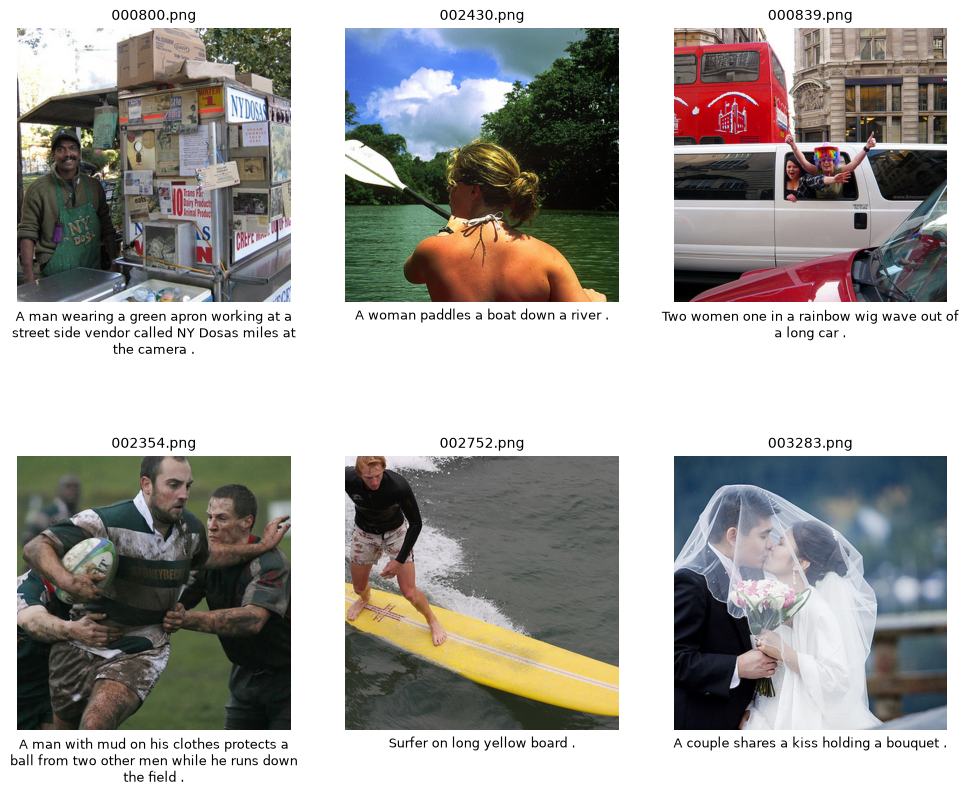

In [7]:
sample_rows = splits['val'][:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 9))
for ax, row in zip(axes.flat, sample_rows):
    with Image.open(NOTEBOOK_DIR / row['image']) as image:
        ax.imshow(image)
    ax.axis('off')
    ax.set_title(row['source_name'], fontsize=10)
    ax.text(0.5, -0.025, textwrap.fill(row['caption'], 43), transform=ax.transAxes,
            ha='center', va='top', fontsize=9)
fig.subplots_adjust(hspace=0.38, bottom=0.13, top=0.95)
fig.savefig(ARTIFACTS / 'dataset_samples.png', dpi=140, bbox_inches='tight')
plt.show()

In [8]:
def load_text_components(local_only):
    tokenizer = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder='tokenizer',
        revision=MODEL_REVISION, local_files_only=local_only)
    encoder = CLIPTextModel.from_pretrained(MODEL_ID, subfolder='text_encoder',
        revision=MODEL_REVISION, local_files_only=local_only, use_safetensors=True)
    return tokenizer, encoder

try:
    tokenizer, text_encoder = load_text_components(local_only=True)
    print('Loaded the pinned CLIP checkpoint from local cache.')
except OSError:
    tokenizer, text_encoder = load_text_components(local_only=False)
    print('Downloaded the pinned CLIP checkpoint.')
text_encoder = text_encoder.to(DEVICE).eval()
text_encoder.requires_grad_(False)
MAX_LENGTH = tokenizer.model_max_length
HIDDEN_SIZE = text_encoder.config.hidden_size
record_check('sd15_text_interface', MAX_LENGTH == 77 and HIDDEN_SIZE == 768)

def encode_texts(texts):
    tokens = tokenizer(texts, padding='max_length', truncation=True,
                       max_length=MAX_LENGTH, return_tensors='pt')
    ids = tokens.input_ids.to(DEVICE)
    mask = tokens.attention_mask.to(DEVICE) if getattr(text_encoder.config, 'use_attention_mask', False) else None
    with torch.inference_mode():
        result = text_encoder(ids, attention_mask=mask).last_hidden_state
    return result.cpu()

print('Model revision:', MODEL_REVISION)
print('Text interface:', MAX_LENGTH, 'tokens x', HIDDEN_SIZE, 'features')
print('Trainable encoder parameters:', sum(p.numel() for p in text_encoder.parameters() if p.requires_grad))

Loaded the pinned CLIP checkpoint from local cache.
Model revision: 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
Text interface: 77 tokens x 768 features
Trainable encoder parameters: 0


In [9]:
embedding_dir = ARTIFACTS / 'embeddings'
embedding_dir.mkdir(exist_ok=True)
captions = [row['caption'] for row in rows]
token_lengths = [len(tokenizer.encode(text, truncation=False)) for text in captions]
embedding_index, encoded, all_finite = [], 0, True
encode_started = time.perf_counter()
for begin in range(0, len(rows), ENCODE_BATCH_SIZE):
    batch_rows = rows[begin:begin + ENCODE_BATCH_SIZE]
    batch_embeddings = encode_texts([row['caption'] for row in batch_rows])
    assert list(batch_embeddings.shape) == [len(batch_rows), MAX_LENGTH, HIDDEN_SIZE]
    all_finite = all_finite and bool(torch.isfinite(batch_embeddings).all())
    filename = f'caption_{begin:05d}.pt'
    torch.save({'embeddings': batch_embeddings, 'ids': [r['id'] for r in batch_rows],
                'splits': [r['split'] for r in batch_rows]}, embedding_dir / filename)
    embedding_index.append({'file': filename, 'rows': len(batch_rows), 'start': begin,
                            'sha256': file_sha256(embedding_dir / filename)})
    encoded += len(batch_rows)
    if encoded % 100 < ENCODE_BATCH_SIZE or encoded == len(rows):
        print(f'Encoded {encoded}/{len(rows)} captions', flush=True)
encoding_seconds = time.perf_counter() - encode_started
record_check('all_caption_embeddings_finite', all_finite)
record_check('all_caption_embeddings_saved', encoded == N_PAIRS)
embedding_summary = {'model_id': MODEL_ID, 'revision': MODEL_REVISION, 'dtype': 'float32',
                     'shape': [encoded, MAX_LENGTH, HIDDEN_SIZE], 'seconds': encoding_seconds,
                     'captions_per_second': encoded / encoding_seconds,
                     'truncated_captions': sum(n > MAX_LENGTH for n in token_lengths),
                     'min_tokens': min(token_lengths), 'max_tokens': max(token_lengths),
                     'median_tokens': float(np.median(token_lengths)), 'shards': embedding_index}
write_json(embedding_dir / 'index.json', embedding_summary)
print(f'Encoded shape: [{encoded}, {MAX_LENGTH}, {HIDDEN_SIZE}]')
print(f'Time: {encoding_seconds:.2f}s; truncated captions: {embedding_summary["truncated_captions"]}')

Encoded 104/3000 captions
Encoded 200/3000 captions
Encoded 304/3000 captions
Encoded 400/3000 captions
Encoded 504/3000 captions
Encoded 600/3000 captions
Encoded 704/3000 captions
Encoded 800/3000 captions
Encoded 904/3000 captions
Encoded 1000/3000 captions
Encoded 1104/3000 captions
Encoded 1200/3000 captions
Encoded 1304/3000 captions
Encoded 1400/3000 captions
Encoded 1504/3000 captions
Encoded 1600/3000 captions
Encoded 1704/3000 captions
Encoded 1800/3000 captions
Encoded 1904/3000 captions
Encoded 2000/3000 captions
Encoded 2104/3000 captions
Encoded 2200/3000 captions
Encoded 2304/3000 captions
Encoded 2400/3000 captions
Encoded 2504/3000 captions
Encoded 2600/3000 captions
Encoded 2704/3000 captions
Encoded 2800/3000 captions
Encoded 2904/3000 captions
Encoded 3000/3000 captions
Encoded shape: [3000, 77, 768]
Time: 75.29s; truncated captions: 0


,source_image,caption,tokens_before_truncation,embedding_shape,finite
0,000800.png,A man wearing a green apron working at a stree...,23,77 x 768,True
1,002430.png,A woman paddles a boat down a river .,12,77 x 768,True
2,000839.png,Two women one in a rainbow wig wave out of a l...,16,77 x 768,True
3,002354.png,A man with mud on his clothes protects a ball ...,23,77 x 768,True
4,002752.png,Surfer on long yellow board .,8,77 x 768,True


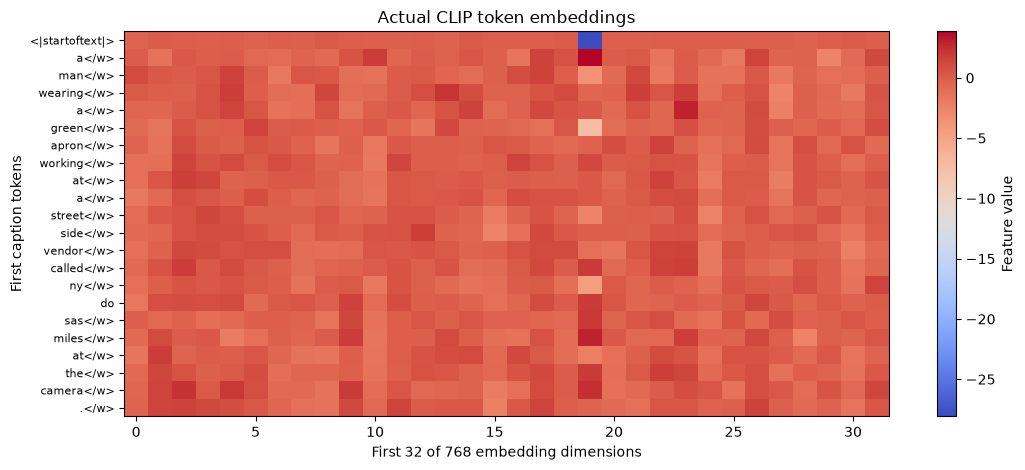

,check,result
0,required_pair_count,PASS
1,unique_ids_and_images,PASS
2,image_disjoint_splits,PASS
3,captions_nonempty_and_normalized,PASS
4,caption_cleaner_example,PASS
5,all_images_rgb_512,PASS
6,training_tensor_shape_and_range,PASS
7,sd15_text_interface,PASS
8,all_caption_embeddings_finite,PASS
9,all_caption_embeddings_saved,PASS


Repeated-prompt maximum absolute difference: 0.0


In [10]:
test_rows = splits['val'][:5]
test_captions = [r['caption'] for r in test_rows]
test_embeddings = encode_texts(test_captions)
test_tokens = tokenizer(test_captions, padding='max_length', truncation=True,
                        max_length=MAX_LENGTH, return_tensors='pt')
sample_table = pd.DataFrame([{
    'source_image': row['source_name'], 'caption': row['caption'],
    'tokens_before_truncation': len(tokenizer.encode(row['caption'], truncation=False)),
    'embedding_shape': f'{MAX_LENGTH} x {HIDDEN_SIZE}',
    'finite': bool(torch.isfinite(test_embeddings[i]).all()),
} for i, row in enumerate(test_rows)])
display(sample_table)
sample_table.to_csv(ARTIFACTS / 'sample_tests.csv', index=False)

repeated = encode_texts([test_captions[0]])
repeated_again = encode_texts([test_captions[0]])
max_repeat_difference = float((repeated - repeated_again).abs().max())
record_check('repeated_prompt_reproducible', torch.allclose(repeated, repeated_again, atol=1e-6, rtol=1e-5))
changed = encode_texts(['A red car is parked beside a quiet road.'])
record_check('different_prompt_changes_embedding', not torch.allclose(repeated, changed))
empty = encode_texts([''])
record_check('empty_prompt_valid_conditioning', list(empty.shape) == [1, 77, 768] and torch.isfinite(empty).all() and not torch.equal(empty, torch.zeros_like(empty)))
long_prompt = 'a small dog running across a green field ' * 30
long_count = len(tokenizer.encode(long_prompt, truncation=False, verbose=False))
long_embedding = encode_texts([long_prompt])
record_check('long_prompt_truncated_to_77', long_count > 77 and list(long_embedding.shape) == [1, 77, 768])

first_shard = torch.load(embedding_dir / embedding_index[0]['file'], map_location='cpu', weights_only=True)
record_check('saved_embedding_roundtrip', first_shard['ids'] == [r['id'] for r in rows[:ENCODE_BATCH_SIZE]] and list(first_shard['embeddings'].shape) == [ENCODE_BATCH_SIZE, 77, 768])

visible_tokens = tokenizer.convert_ids_to_tokens(test_tokens.input_ids[0].tolist())
count = min(int(test_tokens.attention_mask[0].sum()), 22)
fig, ax = plt.subplots(figsize=(11, 4.8))
plot = ax.imshow(test_embeddings[0, :count, :32].numpy(), aspect='auto', cmap='coolwarm')
ax.set_yticks(range(count), visible_tokens[:count], fontsize=8)
ax.set(xlabel='First 32 of 768 embedding dimensions', ylabel='First caption tokens', title='Actual CLIP token embeddings')
fig.colorbar(plot, ax=ax, label='Feature value')
fig.tight_layout()
fig.savefig(ARTIFACTS / 'token_embeddings.png', dpi=140)
plt.show()
display(pd.DataFrame([{'check': name, 'result': 'PASS' if passed else 'FAIL'} for name, passed in checks.items()]))
print('Repeated-prompt maximum absolute difference:', max_repeat_difference)

In [11]:
from diffusers import StableDiffusionPipeline, DDIMScheduler

GENERATION_PROMPTS = [
    {'id': 'p01', 'prompt': 'A brown dog jumps over a fallen log in a green park.'},
    {'id': 'p02', 'prompt': 'Two people in red jackets walk along a snowy mountain trail.'},
    {'id': 'p03', 'prompt': 'A cyclist in a yellow shirt rides past a brick building.'},
    {'id': 'p04', 'prompt': 'A child in a blue coat holds a red umbrella on a rainy street.'},
    {'id': 'p05', 'prompt': 'Three people play basketball on an outdoor court at sunset.'},
]
GENERATION_SETTINGS = {'height': 512, 'width': 512, 'steps': 30, 'guidance': 7.5,
                       'scheduler': 'ddim', 'spacing': 'leading', 'seed': SEED,
                       'embedding': 'clip_last', 'eta': 0.0}
generation_dir = ARTIFACTS / 'prompt_image_tests'
generation_dir.mkdir(exist_ok=True)
generation_dtype = torch.float16 if DEVICE == 'cuda' else torch.float32
load_started = time.perf_counter()
pipeline_args = dict(revision=MODEL_REVISION, torch_dtype=generation_dtype,
                     use_safetensors=True, tokenizer=tokenizer, text_encoder=text_encoder)
try:
    pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, local_files_only=True, **pipeline_args)
except OSError:
    pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, local_files_only=False, **pipeline_args)
pipe.to(DEVICE, dtype=generation_dtype)
pipe.enable_vae_slicing()
pipe.set_progress_bar_config(disable=True)
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config, timestep_spacing='leading')
generation_metadata = {'status': 'running', 'model_id': MODEL_ID, 'revision': MODEL_REVISION,
                       'device': DEVICE, 'dtype': str(generation_dtype),
                       'settings': GENERATION_SETTINGS,
                       'safety_checker_enabled': pipe.safety_checker is not None,
                       'model_load_seconds': time.perf_counter() - load_started}
write_json(generation_dir / 'run.json', generation_metadata)
generation_records = []
with torch.inference_mode():
    for i, row in enumerate(GENERATION_PROMPTS):
        seed = SEED + i
        generator = torch.Generator(device='cpu').manual_seed(seed)
        positive = encode_texts([row['prompt']]).to(device=DEVICE, dtype=generation_dtype)
        negative = encode_texts(['']).to(device=DEVICE, dtype=generation_dtype)
        def report_step(pipeline, step_index, timestep, callback_kwargs):
            if (step_index + 1) % 10 == 0:
                print(f"{row['id']}: denoising step {step_index + 1}/30", flush=True)
            return callback_kwargs
        print(f"Generating {i+1}/5: {row['prompt']}", flush=True)
        if DEVICE == 'cuda':
            torch.cuda.synchronize()
        started = time.perf_counter()
        result = pipe(prompt_embeds=positive, negative_prompt_embeds=negative,
                      guidance_scale=GENERATION_SETTINGS['guidance'],
                      num_inference_steps=GENERATION_SETTINGS['steps'],
                      height=GENERATION_SETTINGS['height'], width=GENERATION_SETTINGS['width'],
                      generator=generator, eta=0.0, callback_on_step_end=report_step)
        if DEVICE == 'cuda':
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - started
        destination = generation_dir / f"{row['id']}.png"
        result.images[0].save(destination)
        record = dict(row, image=destination.relative_to(NOTEBOOK_DIR).as_posix(),
                      seed=seed, seconds=elapsed, sha256=file_sha256(destination),
                      safety_flag=(bool(result.nsfw_content_detected[0])
                                   if result.nsfw_content_detected is not None else None))
        generation_records.append(record)
        with (generation_dir / 'manifest.jsonl').open('w', encoding='utf-8') as handle:
            for item in generation_records:
                handle.write(json.dumps(item, ensure_ascii=False) + '\n')
        print(f"Saved {row['id']}: {elapsed:.2f}s, seed {seed}", flush=True)

record_check('five_prompt_images_saved', len(generation_records) == 5 and
             all((NOTEBOOK_DIR / r['image']).is_file() for r in generation_records))
sizes_valid = True
for row in generation_records:
    with Image.open(NOTEBOOK_DIR / row['image']) as image:
        sizes_valid = sizes_valid and image.size == (512, 512) and image.mode == 'RGB'
record_check('generated_images_rgb_512', sizes_valid)
record_check('generated_prompt_seed_mapping',
             [r['prompt'] for r in generation_records] == [r['prompt'] for r in GENERATION_PROMPTS]
             and [r['seed'] for r in generation_records] == list(range(SEED, SEED + 5)))
generation_metadata.update(status='complete', completed=len(generation_records),
                           total_inference_seconds=sum(r['seconds'] for r in generation_records),
                           timesteps=[float(t) for t in pipe.scheduler.timesteps])
write_json(generation_dir / 'run.json', generation_metadata)
generation_summary = dict(generation_metadata, records=generation_records)
display(pd.DataFrame(generation_records)[['id', 'prompt', 'seed', 'seconds', 'safety_flag']])

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.
Loading pipeline components...: 100%|██████████| 7/7 [00:00<00:00, 18.89it/s]

Generating 1/5: A brown dog jumps over a fallen log in a green park.


p01: denoising step 10/30
p01: denoising step 20/30
p01: denoising step 30/30
Saved p01: 440.78s, seed 42
Generating 2/5: Two people in red jackets walk along a snowy mountain trail.
p02: denoising step 10/30
p02: denoising step 20/30
p02: denoising step 30/30
Saved p02: 422.08s, seed 43
Generating 3/5: A cyclist in a yellow shirt rides past a brick building.
p03: denoising step 10/30
p03: denoising step 20/30
p03: denoising step 30/30
Saved p03: 492.69s, seed 44
Generating 4/5: A child in a blue coat holds a red umbrella on a rainy street.
p04: denoising step 10/30
p04: denoising step 20/30
p04: denoising step 30/30
Saved p04: 425.88s, seed 45
Generating 5/5: Three people play basketball on an outdoor court at sunset.
p05: denoising step 10/30
p05: denoising step 20/30
p05: denoising step 30/30
Saved p05: 346.48s, seed 46


,id,prompt,seed,seconds,safety_flag
0,p01,A brown dog jumps over a fallen log in a green...,42,440.784985,False
1,p02,Two people in red jackets walk along a snowy m...,43,422.079122,False
2,p03,A cyclist in a yellow shirt rides past a brick...,44,492.690421,False
3,p04,A child in a blue coat holds a red umbrella on...,45,425.884358,False
4,p05,Three people play basketball on an outdoor cou...,46,346.477430,False


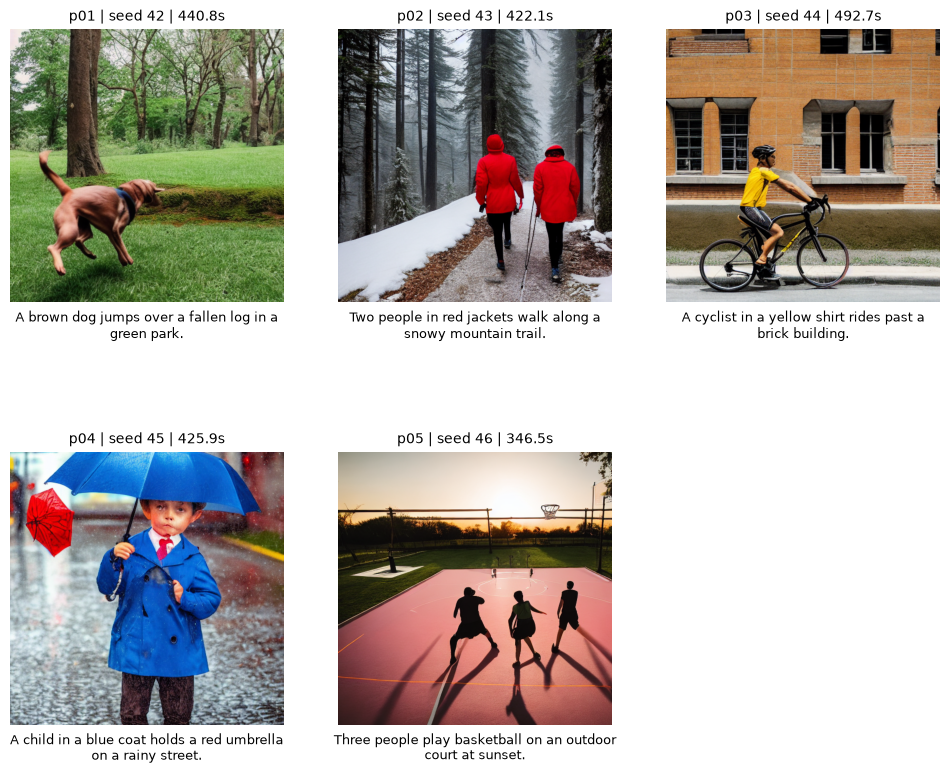

In [12]:
# Show every generated sample in prompt order, without selecting favorable images.
fig, axes = plt.subplots(2, 3, figsize=(12, 9))
for ax in axes.flat:
    ax.axis('off')
for ax, row in zip(axes.flat, generation_records):
    with Image.open(NOTEBOOK_DIR / row['image']) as image:
        ax.imshow(image)
    ax.set_title(f"{row['id']} | seed {row['seed']} | {row['seconds']:.1f}s", fontsize=10)
    ax.text(0.5, -0.025, textwrap.fill(row['prompt'], 43), transform=ax.transAxes,
            ha='center', va='top', fontsize=9)
fig.subplots_adjust(hspace=0.38, bottom=0.13, top=0.94)
fig.savefig(ARTIFACTS / 'five_prompt_images.png', dpi=140, bbox_inches='tight')
plt.show()

# Compact, unaltered sample strip for the one-page proposal.
fig, axes = plt.subplots(1, 5, figsize=(12, 2.7))
for ax, row in zip(axes, generation_records):
    with Image.open(NOTEBOOK_DIR / row['image']) as image:
        ax.imshow(image)
    ax.set_title(row['id'], fontsize=11)
    ax.axis('off')
fig.tight_layout(pad=0.25)
fig.savefig(ARTIFACTS / 'five_prompt_strip.png', dpi=180, bbox_inches='tight')
plt.close(fig)

In [13]:
summary = {
    'status': 'complete', 'started_utc': STARTED_UTC,
    'completed_utc': datetime.now(timezone.utc).isoformat(),
    'environment': environment, 'dataset': dataset_card,
    'embedding': {k:v for k,v in embedding_summary.items() if k != 'shards'},
    'sample_tests': sample_table.to_dict(orient='records'),
    'generation': generation_summary,
    'checks': checks, 'checks_passed': sum(checks.values()),
    'repeat_max_absolute_difference': max_repeat_difference,
    'long_prompt_token_count': long_count,
    'scope': 'Executed data preparation, frozen text encoding and five pretrained prompt-to-image tests; no LoRA training.',
}
write_json(ARTIFACTS / 'execution_summary.json', summary)
write_json(ARTIFACTS / 'environment.json', environment)
display(Markdown(f"**Completed:** {N_PAIRS:,} pairs, splits {len(splits['train'])}/{len(splits['val'])}/{len(splits['test'])}; "
                 f"{encoded:,} CLIP sequences of shape 77 x 768; {len(generation_records)} generated images; {sum(checks.values())}/{len(checks)} checks passed."))
print('Measured evidence:', ARTIFACTS / 'execution_summary.json')

**Completed:** 3,000 pairs, splits 2400/300/300; 3,000 CLIP sequences of shape 77 x 768; 5 generated images; 18/18 checks passed.

Measured evidence: /Users/snehamishra/Documents/DL2026FALL/IE7615_Generative_Project/artifacts/execution_summary.json
